In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [6]:
data = pd.read_csv("/content/drive/MyDrive/month_2_sentiment_analysis_dataset_10000.csv")

In [7]:
data.head()

,review_id,review_text,sentiment,category,source
0,1,This product exceeded my expectations in sever...,Positive,Books,Online Store
1,2,The item is uncomfortable to use and poorly de...,Negative,Books,Online Store
2,3,The product comes with a charging adapter and ...,Neutral,Travel,Customer Survey
3,4,Customer support was slow and did not solve my...,Negative,Home & Kitchen,Website
4,5,"The design is simple, attractive, and comforta...",Positive,Sports,Online Store


In [8]:
data.tail()

,review_id,review_text,sentiment,category,source
9995,9996,The battery drains quickly and does not last a...,Negative,Electronics,Customer Survey
9996,9997,I have been using the product for about one we...,Neutral,Books,Mobile App
9997,9998,The box included the accessories listed in the...,Neutral,Books,Website
9998,9999,"I really like this product; it is useful, reli...",Positive,Electronics,Online Store
9999,10000,The battery lasts a long time and charges quic...,Positive,Travel,Mobile App


In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   review_id    10000 non-null  int64 
 1   review_text  10000 non-null  object
 2   sentiment    10000 non-null  object
 3   category     10000 non-null  object
 4   source       10000 non-null  object
dtypes: int64(1), object(4)
memory usage: 390.8+ KB


In [10]:
data.describe()

,review_id
count,10000.00000
mean,5000.50000
std,2886.89568
min,1.00000
25%,2500.75000
50%,5000.50000
75%,7500.25000
max,10000.00000


In [11]:
data.isnull().sum()

,0
review_id,0
review_text,0
sentiment,0
category,0
source,0


In [12]:
data.shape

(10000, 5)

In [13]:
data.dtypes

,0
review_id,int64
review_text,object
sentiment,object
category,object
source,object


In [14]:
data.columns

Index(['review_id', 'review_text', 'sentiment', 'category', 'source'], dtype='object')

In [15]:
data.duplicated().sum()

np.int64(0)

In [16]:
print(data['sentiment'].unique())

['Positive' 'Negative' 'Neutral']


In [17]:
print(data['sentiment'].value_counts())

sentiment
Positive    3334
Negative    3333
Neutral     3333
Name: count, dtype: int64


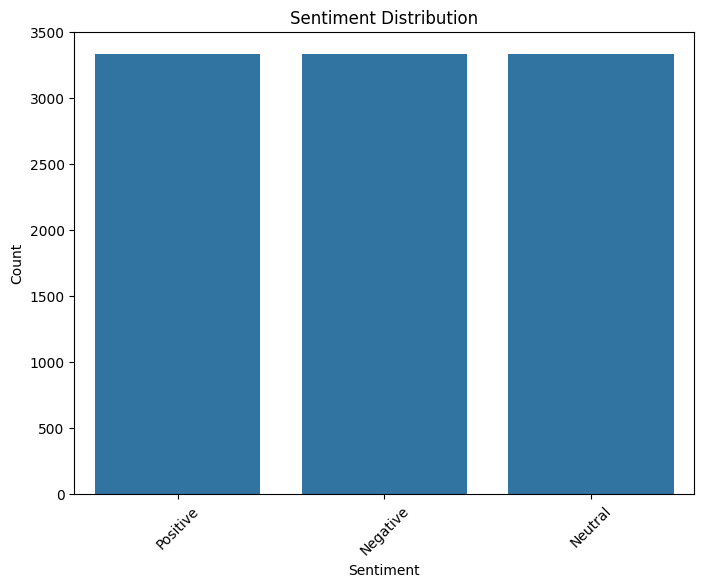

In [18]:
plt.figure(figsize=(8, 6))
sns.countplot(data=data, x='sentiment', order=data['sentiment'].value_counts().index)
plt.title('Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

In [19]:
X = data['review_text']
y = data['sentiment']

In [20]:
X.shape

(10000,)

In [21]:
y.shape

(10000,)

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42, stratify=y)

In [25]:
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (8000,)
X_test shape: (2000,)
y_train shape: (8000,)
y_test shape: (2000,)


In [40]:
lr_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(lowercase=True, stop_words=None, ngram_range=(1,2), max_features=5000, sublinear_tf=True)),
    ('lr', LogisticRegression(max_iter=2000, random_state=42))
])

In [41]:
naive_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(lowercase=True, stop_words=None, ngram_range=(1,2), max_features=5000, sublinear_tf=True)),
    ('naive', MultinomialNB())
])

In [42]:
bow_lr_pipeline = Pipeline([
    ('bow', CountVectorizer(lowercase=True, stop_words=None, ngram_range=(1,2), max_features=5000)),
    ('lr', LogisticRegression(max_iter=2000, random_state=42))
])

In [43]:
bow_naive_pipeline = Pipeline([
    ('bow', CountVectorizer(lowercase=True, stop_words=None, ngram_range=(1,2), max_features=5000)),
    ('naive', MultinomialNB())
])

In [44]:
pipelines = {
    "TF-IDF + Logistic Regression": lr_pipeline,
    "TF-IDF + Naive Bayes": naive_pipeline,
    "BoW + Logistic Regression": bow_lr_pipeline,
    "BoW + Naive Bayes": bow_naive_pipeline
}

Model: TF-IDF + Logistic Regression
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       667
     Neutral       1.00      1.00      1.00       666
    Positive       1.00      1.00      1.00       667

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



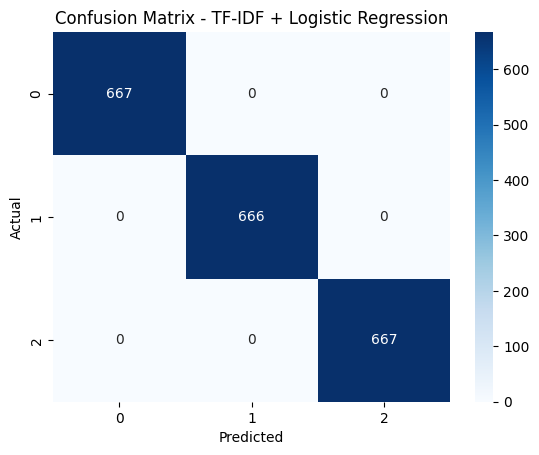



Model: TF-IDF + Naive Bayes
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       667
     Neutral       1.00      1.00      1.00       666
    Positive       1.00      1.00      1.00       667

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



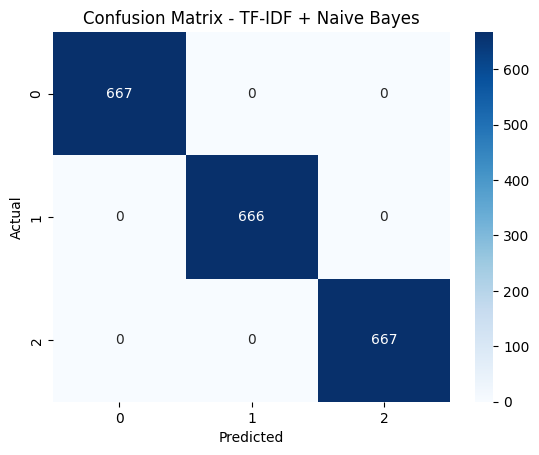



Model: BoW + Logistic Regression
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       667
     Neutral       1.00      1.00      1.00       666
    Positive       1.00      1.00      1.00       667

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



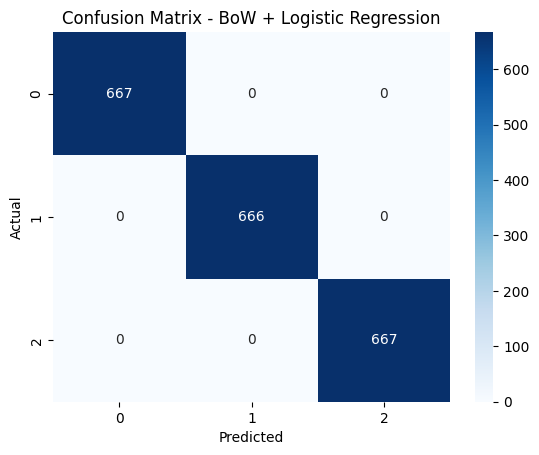



Model: BoW + Naive Bayes
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       667
     Neutral       1.00      1.00      1.00       666
    Positive       1.00      1.00      1.00       667

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



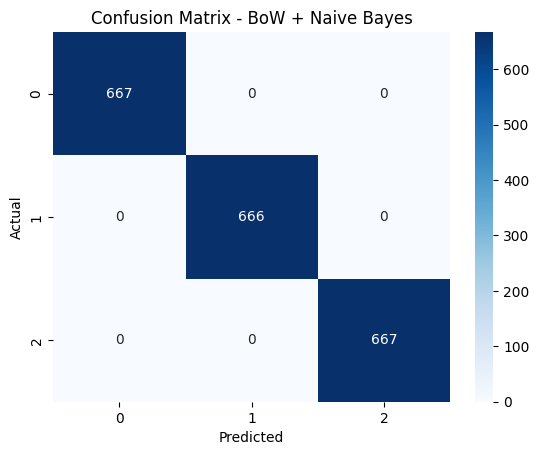

In [54]:
result = []
for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    result.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average='weighted'),
        "Recall": recall_score(y_test, y_pred, average='weighted'),
        "F1 Score": f1_score(y_test, y_pred, average='weighted')
    })
    print(f"Model: {name}")
    print(classification_report(y_test, y_pred))
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()
    print("\n")

In [47]:
result_df = pd.DataFrame(result)
result_df

,Model,Accuracy,Precision,Recall,F1 Score
0,TF-IDF + Logistic Regression,1.0,1.0,1.0,1.0
1,TF-IDF + Naive Bayes,1.0,1.0,1.0,1.0
2,BoW + Logistic Regression,1.0,1.0,1.0,1.0
3,BoW + Naive Bayes,1.0,1.0,1.0,1.0


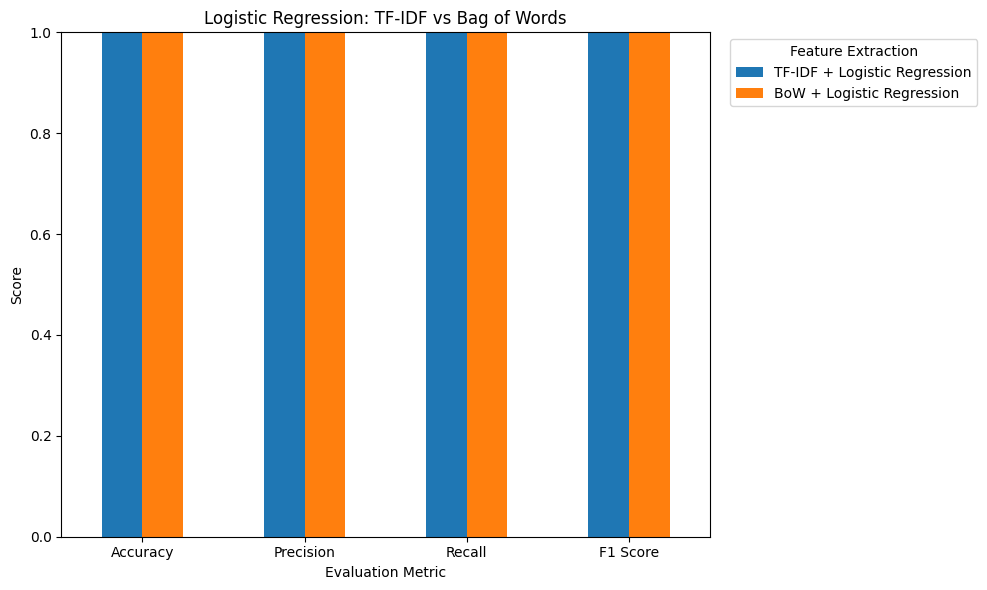

In [57]:
lr_comparison = result_df[
    result_df["Model"].isin([
        "TF-IDF + Logistic Regression",
        "BoW + Logistic Regression"
    ])].copy()
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]
lr_comparison = lr_comparison.set_index("Model").reindex([
    "TF-IDF + Logistic Regression",
    "BoW + Logistic Regression"
])
lr_comparison[metrics].T.plot(
    kind="bar",
    figsize=(10, 6)
)
plt.title("Logistic Regression: TF-IDF vs Bag of Words")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Feature Extraction", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

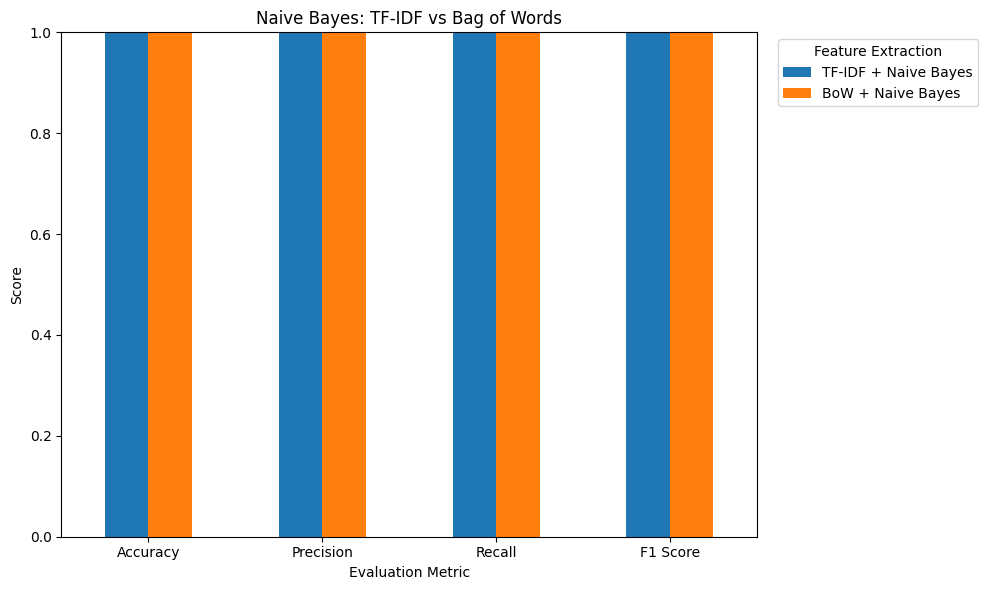

In [58]:
naive_comparison = result_df[
    result_df["Model"].isin([
        "TF-IDF + Naive Bayes",
        "BoW + Naive Bayes"
    ])].copy()
naive_comparison = naive_comparison.set_index("Model").reindex([
    "TF-IDF + Naive Bayes",
    "BoW + Naive Bayes"
])
naive_comparison[metrics].T.plot(
    kind="bar",
    figsize=(10, 6)
)
plt.title("Naive Bayes: TF-IDF vs Bag of Words")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Feature Extraction", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

In [60]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [63]:
model_configs = {
    "TF-IDF + Logistic Regression": (
        Pipeline([
            ("vectorizer", TfidfVectorizer()),
            ("classifier", LogisticRegression(
                max_iter=2000, random_state=42
            ))
        ]),
        {
            "vectorizer__ngram_range": [(1, 1), (1, 2)],
            "vectorizer__max_features": [20000, 50000],
            "classifier__C": [0.5, 1.0, 2.0]
        }
    ),
    "BoW + Logistic Regression": (
        Pipeline([
            ("vectorizer", CountVectorizer()),
            ("classifier", LogisticRegression(
                max_iter=2000, random_state=42
            ))
        ]),
        {
            "vectorizer__ngram_range": [(1, 1), (1, 2)],
            "vectorizer__max_features": [20000, 50000],
            "classifier__C": [0.5, 1.0, 2.0]
        }
    ),
    "TF-IDF + Naive Bayes": (
        Pipeline([
            ("vectorizer", TfidfVectorizer()),
            ("classifier", MultinomialNB())
        ]),
        {
            "vectorizer__ngram_range": [(1, 1), (1, 2)],
            "vectorizer__max_features": [20000, 50000],
            "classifier__alpha": [0.1, 0.5, 1.0]
        }
    ),
    "BoW + Naive Bayes": (
        Pipeline([
            ("vectorizer", CountVectorizer()),
            ("classifier", MultinomialNB())
        ]),
        {
            "vectorizer__ngram_range": [(1, 1), (1, 2)],
            "vectorizer__max_features": [20000, 50000],
            "classifier__alpha": [0.1, 0.5, 1.0]
        }
    )
}


In [67]:
tuned_models = {}
tuning_results = []
for name, (pipeline, param_grid) in model_configs.items():
    print("Tuning:", name)
    grid = GridSearchCV(estimator=pipeline, param_grid=param_grid, scoring="f1_macro", cv=cv, n_jobs=-1, refit=True, verbose=1 )
    grid.fit(X_train, y_train)
    tuned_models[name] = grid.best_estimator_
    tuning_results.append({
        "Model": name,
        "Best CV Macro F1": grid.best_score_,
        "Best Parameters": grid.best_params_
    })
    print("\n")

Tuning: TF-IDF + Logistic Regression
Fitting 5 folds for each of 12 candidates, totalling 60 fits


Tuning: BoW + Logistic Regression
Fitting 5 folds for each of 12 candidates, totalling 60 fits


Tuning: TF-IDF + Naive Bayes
Fitting 5 folds for each of 12 candidates, totalling 60 fits


Tuning: BoW + Naive Bayes
Fitting 5 folds for each of 12 candidates, totalling 60 fits




In [65]:
tuning_df = pd.DataFrame(tuning_results)

In [66]:
tuning_df = tuning_df.sort_values(
    "Best CV Macro F1",
    ascending=False
).reset_index(drop=True)
tuning_df

,Model,Best CV Macro F1,Best Parameters
0,TF-IDF + Logistic Regression,1.0,"{'classifier__C': 0.5, 'vectorizer__max_featur..."
1,BoW + Logistic Regression,1.0,"{'classifier__C': 0.5, 'vectorizer__max_featur..."
2,TF-IDF + Naive Bayes,1.0,"{'classifier__alpha': 0.1, 'vectorizer__max_fe..."
3,BoW + Naive Bayes,1.0,"{'classifier__alpha': 0.1, 'vectorizer__max_fe..."


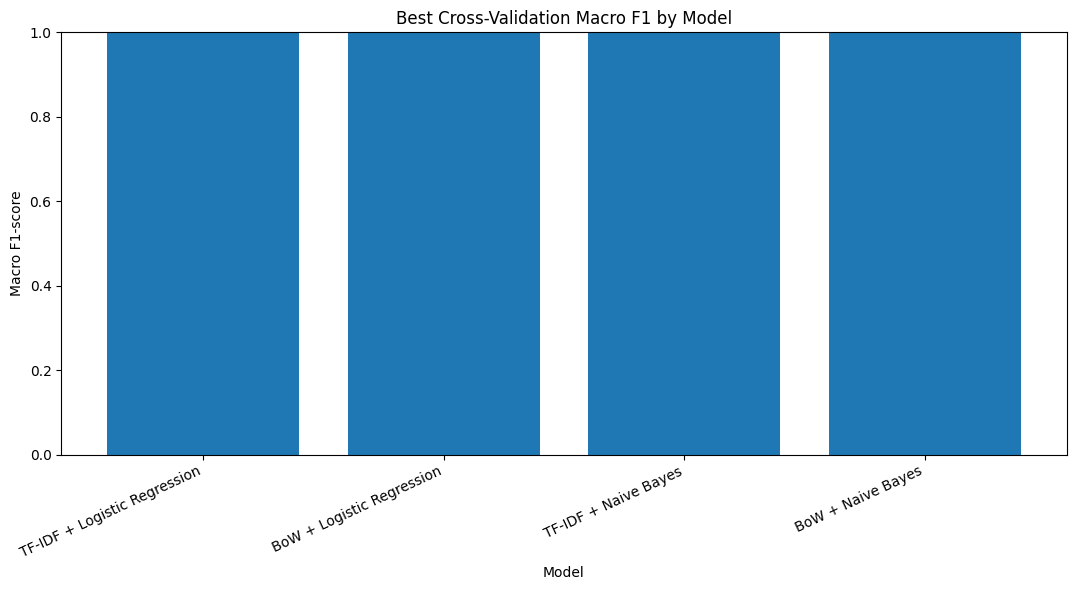

In [68]:
plt.figure(figsize=(11, 6))
plt.bar( tuning_df["Model"], tuning_df["Best CV Macro F1"] )
plt.title("Best Cross-Validation Macro F1 by Model")
plt.ylabel("Macro F1-score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [69]:
best_model_name = tuning_df.iloc[0]["Model"]
best_model = tuned_models[best_model_name]
print("Selected model:", best_model_name)
print("Best cross-validation Macro F1:",
      round(tuning_df.iloc[0]["Best CV Macro F1"], 4))
print("\nBest model parameters:")
print(best_model.get_params())

Selected model: TF-IDF + Logistic Regression
Best cross-validation Macro F1: 1.0

Best model parameters:
{'memory': None, 'steps': [('vectorizer', TfidfVectorizer(max_features=20000)), ('classifier', LogisticRegression(C=0.5, max_iter=2000, random_state=42))], 'transform_input': None, 'verbose': False, 'vectorizer': TfidfVectorizer(max_features=20000), 'classifier': LogisticRegression(C=0.5, max_iter=2000, random_state=42), 'vectorizer__analyzer': 'word', 'vectorizer__binary': False, 'vectorizer__decode_error': 'strict', 'vectorizer__dtype': <class 'numpy.float64'>, 'vectorizer__encoding': 'utf-8', 'vectorizer__input': 'content', 'vectorizer__lowercase': True, 'vectorizer__max_df': 1.0, 'vectorizer__max_features': 20000, 'vectorizer__min_df': 1, 'vectorizer__ngram_range': (1, 1), 'vectorizer__norm': 'l2', 'vectorizer__preprocessor': None, 'vectorizer__smooth_idf': True, 'vectorizer__stop_words': None, 'vectorizer__strip_accents': None, 'vectorizer__sublinear_tf': False, 'vectorizer__to

In [73]:
y_pred = best_model.predict(X_test)
print(f"Selected Model: {best_model_name}")
print(f"Accuracy: {accuracy_score(y_test, y_pred), 4}")
print(f"Macro Precision: {precision_score(y_test, y_pred, average="macro", zero_division=0), 4}" )
print(f"Macro Recall: {recall_score(y_test, y_pred, average="macro", zero_division=0), 4}" )
print(f"Macro F1-Score: {f1_score(y_test, y_pred, average="macro", zero_division=0), 4}" )
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Selected Model: TF-IDF + Logistic Regression
Accuracy: (1.0, 4)
Macro Precision: (1.0, 4)
Macro Recall: (1.0, 4)
Macro F1-Score: (1.0, 4)

Classification Report:
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       667
     Neutral       1.00      1.00      1.00       666
    Positive       1.00      1.00      1.00       667

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



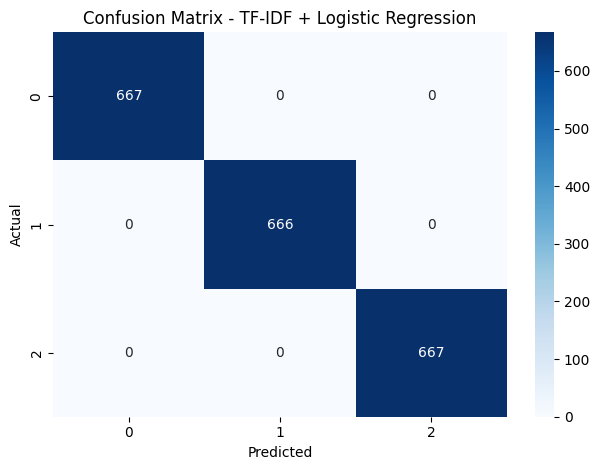

In [75]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

In [78]:
joblib.dump(best_model, "/content/drive/MyDrive/sentiment_analysis.pkl")

['/content/drive/MyDrive/sentiment_analysis.pkl']